# 09 - Final Comparison of All Models and Best Model Selection

This notebook compares **all** models: the original ones (notebooks 02-06, unchanged) and the advanced ones (notebook 08). It then selects the best model by the same rule as before and trains the final pickle.

Rule: highest average of **validation** ROC-AUC, PR-AUC and F2 (dummy ignored). The test set is never used to choose.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve
from src import config as C
from src.select_best_model import load_results, select_best, MODEL_NAMES
table = load_results()
table.drop(columns="params").round(3)

skipped: xgboost (library not installed)
skipped: lightgbm (library not installed)


,model,val_roc_auc,val_pr_auc,val_f2,test_roc_auc,test_pr_auc,test_precision,test_recall,test_specificity,test_f1,test_f2,test_balanced_accuracy,threshold,hr_recall,hr_precision,hr_specificity
0,dummy,0.500,0.022,0.000,0.500,0.020,0.000,0.000,1.000,0.000,0.000,0.500,0.500,NaN,NaN,NaN
1,logistic_regression,0.690,0.095,0.251,0.721,0.094,0.110,0.349,0.942,0.167,0.243,0.645,0.651,NaN,NaN,NaN
2,decision_tree,0.714,0.083,0.261,0.735,0.083,0.148,0.356,0.958,0.209,0.278,0.657,0.843,NaN,NaN,NaN
3,random_forest,0.765,0.102,0.266,0.783,0.102,0.142,0.385,0.952,0.207,0.287,0.669,0.607,NaN,NaN,NaN
4,svm,0.740,0.082,0.237,0.755,0.079,0.090,0.380,0.921,0.146,0.231,0.651,0.435,NaN,NaN,NaN
5,hist_gradient_boosting,0.776,0.107,0.279,0.785,0.104,0.127,0.423,0.940,0.195,0.289,0.682,0.668,0.727,0.047,0.695
6,random_forest_tuned,0.774,0.101,0.274,0.780,0.103,0.118,0.421,0.935,0.185,0.279,0.678,0.578,0.715,0.045,0.688
7,extra_trees,0.756,0.102,0.267,0.781,0.104,0.159,0.351,0.962,0.219,0.283,0.657,0.662,0.723,0.045,0.685


## Metric comparison (test set, balanced / F2 threshold)

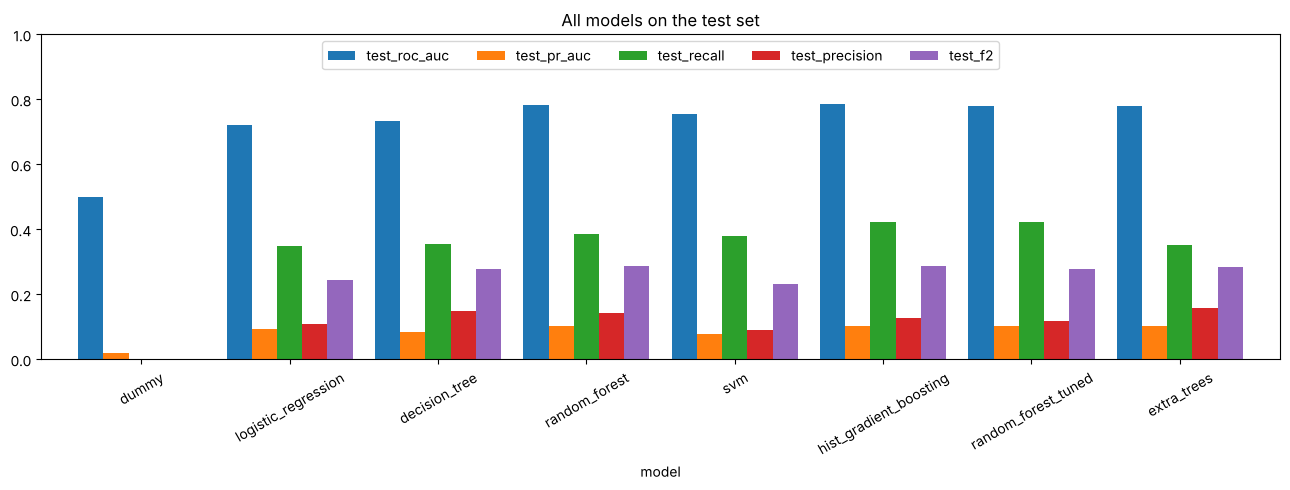

In [2]:
metrics = ["test_roc_auc", "test_pr_auc", "test_recall", "test_precision", "test_f2"]
ax = table.set_index("model")[metrics].plot.bar(figsize=(13, 5), rot=30, width=0.85)
ax.set(title="All models on the test set", ylim=(0, 1)); plt.legend(ncol=5, loc="upper center")
plt.tight_layout(); plt.savefig(C.FIG_DIR / "model_comparison_bars.png", dpi=130); plt.show()

## ROC and Precision-Recall curves on the same test set

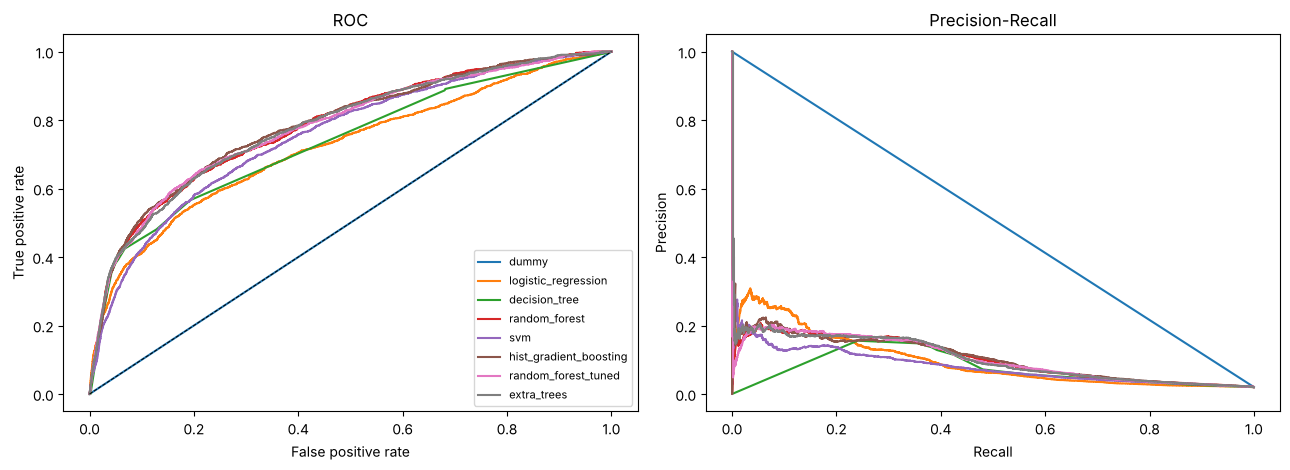

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
for name in table["model"]:
    d = np.load(C.RESULTS_DIR / f"preds_{name}.npz")
    fpr, tpr, _ = roc_curve(d["y_test"], d["p_test"])
    p, r, _ = precision_recall_curve(d["y_test"], d["p_test"])
    ax[0].plot(fpr, tpr, label=name); ax[1].plot(r, p, label=name)
ax[0].plot([0, 1], [0, 1], "k--", lw=.7)
ax[0].set(title="ROC", xlabel="False positive rate", ylabel="True positive rate")
ax[1].set(title="Precision-Recall", xlabel="Recall", ylabel="Precision")
ax[0].legend(fontsize=8); plt.tight_layout()
plt.savefig(C.FIG_DIR / "model_comparison_curves.png", dpi=130); plt.show()

## Two alert modes (advanced models)
Balanced mode uses the F2 threshold. High-sensitivity mode picks, on validation, the threshold that catches at least 70% of sepsis rows. More cases are found but many more alarms are false (low precision). This is the trade-off an ICU must choose.

In [4]:
cols = ["model", "test_recall", "test_precision", "hr_recall", "hr_precision", "hr_specificity"]
modes = table[cols].dropna().rename(columns={"test_recall": "balanced_recall", "test_precision": "balanced_precision",
    "hr_recall": "high_sens_recall", "hr_precision": "high_sens_precision", "hr_specificity": "high_sens_specificity"})
modes.round(3)

,model,balanced_recall,balanced_precision,high_sens_recall,high_sens_precision,high_sens_specificity
5,hist_gradient_boosting,0.423,0.127,0.727,0.047,0.695
6,random_forest_tuned,0.421,0.118,0.715,0.045,0.688
7,extra_trees,0.351,0.159,0.723,0.045,0.685


## Select the best model
The winner's settings are saved in `models/best_model_config.json`.

In [5]:
bundle = select_best()
print("Selected:", bundle["model_name"], "| settings:", bundle["tuned_params"])

skipped: xgboost (library not installed)
skipped: lightgbm (library not installed)
                 model  val_roc_auc  val_pr_auc  val_f2  test_roc_auc  test_pr_auc  test_precision  test_recall  test_specificity  test_f1  test_f2  test_balanced_accuracy  threshold  hr_recall  hr_precision  hr_specificity  val_score
                 dummy        0.500       0.022   0.000         0.500        0.020           0.000        0.000             1.000    0.000    0.000                   0.500      0.500        NaN           NaN             NaN      0.174
   logistic_regression        0.690       0.095   0.251         0.721        0.094           0.110        0.349             0.942    0.167    0.243                   0.645      0.651        NaN           NaN             NaN      0.346
         decision_tree        0.714       0.083   0.261         0.735        0.083           0.148        0.356             0.958    0.209    0.278                   0.657      0.843        NaN           NaN     

## Final pipeline
Train ONLY the selected model with the saved settings and save the single pickle `models/best_model.pkl`.

In [6]:
from src.final_pipeline import train_final
final = train_final()

Saved best_model.pkl: hist_gradient_boosting, threshold 0.668 (high-sensitivity threshold 0.395)
balanced mode   : {'roc_auc': 0.785, 'pr_auc': 0.104, 'threshold': 0.668, 'precision': 0.127, 'recall': 0.423, 'specificity': 0.94, 'f1': 0.195, 'f2': 0.289, 'balanced_accuracy': 0.682}
high sensitivity: {'roc_auc': 0.785, 'pr_auc': 0.104, 'threshold': 0.395, 'precision': 0.047, 'recall': 0.727, 'specificity': 0.695, 'f1': 0.088, 'f2': 0.186, 'balanced_accuracy': 0.711}
